# TP2 — Optimización del moveset ofensivo de Charizard con un Algoritmo Genético

**Grupo 6 — Inteligencia Artificial (UTN FRBA), entrega final.**

Este notebook es una demostración didáctica y ejecutable. No reimplementa nada: importa los módulos de
`src/charizard_ga`, que son los mismos que usan la consola (`scripts/run_ga.py`), el lote de experimentos
(`scripts/run_experiments.py`) y los gráficos (`scripts/make_figures.py`). Todos los números se calculan al
ejecutar las celdas.

Contenido: 1) datos, 2) tabla de tipos, 3) cromosoma y función de aptitud F2 (potencia efectiva),
4) operadores genéticos, 5) una corrida completa con DEAP, 6) resultados del lote y comparación con la
enumeración exhaustiva.

In [1]:
# Configuración: se ubica la carpeta raíz del proyecto (la que contiene config/ y src/) sin rutas absolutas.
import sys
from pathlib import Path

ROOT = Path.cwd()
while not ((ROOT / "config").is_dir() and (ROOT / "src").is_dir()):
    if ROOT.parent == ROOT:
        raise RuntimeError("No se encontró la raíz del proyecto")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import math
import pandas as pd
import matplotlib.pyplot as plt

from charizard_ga.data import load_catalog, load_metadata, TYPE_ORDER
from charizard_ga.config import load_experiments
from charizard_ga.fitness import components, contributions, fitness, validate_moveset
from charizard_ga.ga import run_ga, describe_solution
from charizard_ga.baselines import exhaustive_table, exhaustive_optimum, rank_of

pd.set_option("display.width", 160)
print("Raíz del proyecto:", ROOT.name)

Raíz del proyecto: tp2-charizard-ga


## 1. Datos

Catálogo definitivo: movimientos que Charizard aprende en **Pokémon Escarlata/Púrpura** (grupo de versiones
`scarlet-violet`, Gen 9), según PokéAPI fijada por commit y verificada contra Pokémon Showdown. Se excluyen
movimientos de estado y los casos que la función de aptitud no puede representar (potencia o precisión no
numéricas, golpes múltiples). Ver `data/FUENTES_DATOS.md`.

Para cada movimiento se calcula además su **potencia efectiva**, lo que pega de verdad por turno con Charizard:
es la potencia que usa la aptitud F2.

In [2]:
catalog = load_catalog()
meta = load_metadata()
print(f"M = {catalog.M} movimientos; C(M,4) = {math.comb(catalog.M, 4):,} movesets posibles")
print("Versión del dataset:", catalog.dataset_version, "| excluidos por motivo:", meta["conteos"]["excluidos_por_motivo"])
print(f"Charizard: Ataque {catalog.base_stats['attack']}, Ataque Especial {catalog.base_stats['special-attack']}")
print(f"Potencia efectiva máxima (normaliza P en F2): {catalog.power_eff_max:g} | potencia base máxima (F1): {catalog.power_max}")
# Los movimientos de mayor potencia base: la potencia efectiva descuenta lo que ese número no muestra.
cat_df = pd.DataFrame([vars(m) for m in catalog.moves.values()]).rename(columns={"efectos_ignorados": "efectos"})
cols = ["nombre_es", "tipo_es", "categoria", "potencia", "potencia_efectiva", "precision", "efectos"]
cat_df.sort_values(["potencia", "potencia_efectiva"], ascending=False)[cols].head(12).round(1)

M = 53 movimientos; C(M,4) = 292,825 movesets posibles
Versión del dataset: 6557b19f60a8 | excluidos por motivo: {'POTENCIA_NO_NUMERICA': 3, 'ESTADO': 17, 'PRECISION_NO_NUMERICA': 2}
Charizard: Ataque 84, Ataque Especial 109
Potencia efectiva máxima (normaliza P en F2): 120 | potencia base máxima (F1): 150


,nombre_es,tipo_es,categoria,potencia,potencia_efectiva,precision,efectos
10,Hiperrayo,Normal,special,150,75.0,90,obliga a recargar un turno
28,Anillo Ígneo,Fuego,special,150,75.0,90,obliga a recargar un turno
39,Gigaimpacto,Normal,physical,150,57.8,90,obliga a recargar un turno
26,Puño Certero,Lucha,physical,150,28.9,100,falla si el usuario recibe daño antes de actua...
31,Sofoco,Fuego,special,130,97.5,90,baja estadísticas propias spa -2
38,Onda Certera,Lucha,special,120,120.0,70,
6,Doble Filo,Normal,physical,120,77.2,100,retroceso 33/100 del daño causado
34,Envite Ígneo,Fuego,physical,120,77.2,100,retroceso 33/100 del daño causado
18,Enfado,Dragón,physical,120,69.4,100,bloquea 2-3 turnos y luego confunde al usuario
11,Rayo Solar,Planta,special,120,60.0,100,requiere turno de carga; potencia condicional ...


## 2. Tabla de efectividad

Orientación explícita: **filas = tipo atacante, columnas = tipo defensor**. La cobertura C(x) cuenta los
tipos defensores para los que algún movimiento tiene multiplicador mayor que 1.

In [3]:
chart = pd.DataFrame(catalog.chart).T.loc[list(TYPE_ORDER), list(TYPE_ORDER)]
print("Fuego -> Planta:", chart.loc["fire", "grass"], "| Planta -> Fuego:", chart.loc["grass", "fire"])
print("Eléctrico -> Tierra:", chart.loc["electric", "ground"], "| Tierra -> Eléctrico:", chart.loc["ground", "electric"])
chart.loc[["fire", "flying", "ground", "fighting"]]

Fuego -> Planta: 2.0 | Planta -> Fuego: 0.5
Eléctrico -> Tierra: 0.0 | Tierra -> Eléctrico: 2.0


,normal,fire,water,electric,grass,ice,fighting,poison,ground,flying,psychic,bug,rock,ghost,dragon,dark,steel,fairy
fire,1.0,0.5,0.5,1.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,0.5,1.0,0.5,1.0,2.0,1.0
flying,1.0,1.0,1.0,0.5,2.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,0.5,1.0,1.0,1.0,0.5,1.0
ground,1.0,2.0,1.0,2.0,0.5,1.0,1.0,2.0,1.0,0.0,1.0,0.5,2.0,1.0,1.0,1.0,2.0,1.0
fighting,2.0,1.0,1.0,1.0,1.0,2.0,1.0,0.5,1.0,0.5,0.5,0.5,2.0,0.0,1.0,2.0,2.0,0.5


## 3. Cromosoma y función de aptitud (F2)

Un individuo es una lista de **cuatro IDs de movimientos distintos**. El orden no cambia el significado.

F(x) = 100 × (wC·C + wP·P + wA·A + wS·S + wD·D), con componentes en [0, 1]. Perfil base R1:
wC = 0,40; wP = 0,20; wA = 0,15; wS = 0,15; wD = 0,10.

En la aptitud **F2**, P es la potencia **efectiva** media dividida por la potencia efectiva máxima del catálogo.
La potencia efectiva multiplica la potencia base por factores de modelado (`src/charizard_ga/mechanics.py`):
categoría (los movimientos físicos rinden 84/109 por el Ataque de Charizard), turno de carga o recarga (×0,5),
fallo condicional (×0,25), bloqueo (×0,75), retroceso r (×(1 − r/2)) y caída del propio stat ofensivo. La
versión original **F1** usaba la potencia base; se conserva solo como referencia (configuración ORIG-R1).

Ejemplo de referencia: Lanzallamas, Tajo Aéreo, Pulso Dragón, Rayo Solar.

In [4]:
exps = load_experiments()
w_base = exps["profiles"]["R1"]
example = [catalog.by_slug(s) for s in ["flamethrower", "air-slash", "dragon-pulse", "solar-beam"]]
comp = components(example, catalog)            # F2, la versión por defecto
print("Movimientos:", catalog.names(example))
print("Potencia base:", [catalog.moves[m].potencia for m in example],
      "| efectiva:", [round(catalog.moves[m].potencia_efectiva, 1) for m in example])
print("Tipos cubiertos (", len(comp.covered), "):", [catalog.type_es[t] for t in comp.covered])
print({k: round(v, 6) for k, v in zip("CPASD", comp.as_tuple())})
print("Aportes:", {k: round(v, 4) for k, v in contributions(comp, w_base).items()})
print("F2(x) =", round(fitness(example, catalog, w_base), 6), "| con la versión original, F1(x) =",
      round(fitness(example, catalog, w_base, "F1"), 6))

Movimientos: ['Lanzallamas', 'Tajo Aéreo', 'Pulso Dragón', 'Rayo Solar']
Potencia base: [90, 75, 85, 120] | efectiva: [90.0, 75.0, 85.0, 60.0]
Tipos cubiertos ( 9 ): ['Agua', 'Planta', 'Hielo', 'Lucha', 'Tierra', 'Bicho', 'Roca', 'Dragón', 'Acero']
{'C': 0.5, 'P': 0.645833, 'A': 0.9875, 'S': 0.5, 'D': 1.0}
Aportes: {'C': 20.0, 'P': 12.9167, 'A': 14.8125, 'S': 7.5, 'D': 10.0}
F2(x) = 65.229167 | con la versión original, F1(x) = 64.645833


In [5]:
# Restricciones duras: aptitud 0 para individuos inválidos.
a, b, c, d = example
for label, ms in {"3 movimientos": [a, b, c], "repetido": [a, a, b, c], "fuera del catálogo (Danza Espada)": [a, b, c, 14]}.items():
    print(f"{label:35s} -> válido={validate_moveset(ms, catalog)[0]}, F={fitness(ms, catalog, w_base)}")
# Invariancia frente a permutaciones del mismo moveset.
import itertools
print("Valores distintos entre las 24 permutaciones:", len({fitness(list(p), catalog, w_base) for p in itertools.permutations(example)}))

3 movimientos                       -> válido=False, F=0.0
repetido                            -> válido=False, F=0.0
fuera del catálogo (Danza Espada)   -> válido=False, F=0.0
Valores distintos entre las 24 permutaciones: 1


## 4. Operadores genéticos

Configuración base y variantes que se comparan en el lote:

- **Inicialización**: 4 movimientos muestreados sin reemplazo.
- **Selección**: torneo de tamaño 3 (`tools.selTournament`). Variantes: ruleta (con selección uniforme si todas
  las aptitudes valen 0), ranking lineal y control sobre número esperado.
- **Cruza** (por pareja, p = 0,80): **cruza de conjuntos**. Los movimientos que comparten ambos padres pasan a
  los dos hijos y el resto se completa al azar con los demás genes de los padres, así que nunca genera repetidos.
  Variantes: binomial aleatoria (uniforme, intercambio por posición con p = 0,5) y simple (un punto), ambas
  seguidas de **reparación** de duplicados.
- **Mutación** (por individuo, p = 0,10): reemplaza un gen al azar por un movimiento ausente. Variantes:
  p = 0,20 y mutación adaptativa (sube hasta 0,40 cuando la población converge).
- **Reemplazo** generacional con **elitismo** de 2 individuos y **paro** a las 200 generaciones (variante:
  30 generaciones seguidas sin mejora).

Demostración: dos padres que comparten un movimiento (Terremoto) en posiciones distintas.

In [6]:
import random
from deap import creator
from charizard_ga.ga import ensure_deap_types, INDIVIDUAL_CLASS
from charizard_ga.operators import cx_set, cx_uniform_repair, mut_replace_one, OperatorCounters

ensure_deap_types()                      # se puede reejecutar sin advertencias de creator.create
Ind = getattr(creator, INDIVIDUAL_CLASS)
eq, hur, fb, fl, cr = (catalog.by_slug(s) for s in ["earthquake", "hurricane", "focus-blast", "flare-blitz", "crunch"])
counters = OperatorCounters()
p1, p2 = Ind([eq, hur, fb, fl]), Ind([cr, eq, a, b])   # Terremoto está en la posición 0 de p1 y en la 1 de p2
print("Padres:", catalog.names(p1), "x", catalog.names(p2))

random.seed(1)
c1, c2 = Ind(p1), Ind(p2)
cx_set(c1, c2, counters)
print("Cruza de conjuntos:", catalog.names(c1), "|", catalog.names(c2))
print("  ¿Terremoto en los dos hijos?", eq in c1 and eq in c2,
      "| ¿hijos válidos sin reparar?", validate_moveset(c1, catalog)[0] and validate_moveset(c2, catalog)[0])

# Con la binomial aleatoria el gen compartido puede quedar repetido en un hijo y faltar en el otro: la reparación
# completa el repetido con otro gen de los padres y Terremoto se pierde. Se busca la primera semilla en que ocurre.
for seed in range(100):
    random.seed(seed)
    u1, u2 = Ind(p1), Ind(p2)
    cx_uniform_repair(u1, u2, 0.5, catalog.ids, counters)
    if eq not in u1 or eq not in u2:
        break
print(f"Binomial aleatoria + reparación (semilla {seed}):", catalog.names(u1), "|", catalog.names(u2))

m = Ind(p1); mut_replace_one(m, catalog.ids, counters)
print("Mutación:", catalog.names(p1), "->", catalog.names(m))

Padres: ['Terremoto', 'Vendaval', 'Onda Certera', 'Envite Ígneo'] x ['Triturar', 'Terremoto', 'Lanzallamas', 'Tajo Aéreo']
Cruza de conjuntos: ['Terremoto', 'Onda Certera', 'Lanzallamas', 'Vendaval'] | ['Terremoto', 'Envite Ígneo', 'Vendaval', 'Triturar']
  ¿Terremoto en los dos hijos? True | ¿hijos válidos sin reparar? True
Binomial aleatoria + reparación (semilla 1): ['Triturar', 'Vendaval', 'Onda Certera', 'Tajo Aéreo'] | ['Terremoto', 'Tajo Aéreo', 'Lanzallamas', 'Envite Ígneo']
Mutación: ['Terremoto', 'Vendaval', 'Onda Certera', 'Envite Ígneo'] -> ['Terremoto', 'Vendaval', 'Onda Certera', 'Sofoco']


## 5. Corrida completa con DEAP (R1, semilla 42)

Se ejecuta la corrida principal R1 (aptitud F2, cruza de conjuntos) y se comprueba que reproduce exactamente
el log guardado por el lote (`results/runs/R1/seed_42_log.csv`).

In [7]:
exp_r1 = next(c for c in exps["configs"] if c.config_id == "R1")
print("Parámetros:", exp_r1.ga.to_dict())
res = run_ga(catalog, exp_r1.weights, exp_r1.ga, seed=42, config_id="R1", verbose=True, print_every=40)
# round_trip: los logs guardan cada float con todos sus dígitos y el lector por defecto de pandas puede redondear el último.
saved = pd.read_csv(ROOT / "results" / "runs" / "R1" / "seed_42_log.csv", float_precision="round_trip")
new = pd.DataFrame(res.log)
same = new[["aptitud_max", "aptitud_media", "mejor_acumulada"]].equals(saved[["aptitud_max", "aptitud_media", "mejor_acumulada"]])
print("¿Coincide con el log guardado?", same)
sol = describe_solution(res.best_moveset, catalog, exp_r1.weights, w_base)
pd.DataFrame(sol["movimientos"])[["nombre_es", "tipo_es", "potencia", "potencia_efectiva", "precision", "categoria", "stab"]].round(1)

Parámetros: {'population_size': 100, 'generations': 200, 'selection': 'tournament', 'tournament_size': 3, 'crossover': 'set', 'cx_prob': 0.8, 'cx_indpb': 0.5, 'mutation_prob': 0.1, 'mutation_mode': 'simple', 'mutation_prob_max': 0.4, 'convergence_threshold': 0.9, 'elitism': 2, 'stop_criterion': 'generations', 'patience': 30, 'fitness_version': 'F2'}
gen   0 | max 69.2395 | media 54.8845 | mejor acumulada 69.2395 | distintas 100 | mejor: earthquake|brick-break|flare-blitz|hurricane
gen  40 | max 71.5096 | media 71.1130 | mejor acumulada 71.5096 | distintas  10 | mejor: earthquake|fire-blast|focus-blast|hurricane
gen  80 | max 71.5096 | media 71.0440 | mejor acumulada 71.5096 | distintas  11 | mejor: earthquake|fire-blast|focus-blast|hurricane
gen 120 | max 71.5096 | media 71.2219 | mejor acumulada 71.5096 | distintas   8 | mejor: earthquake|fire-blast|focus-blast|hurricane


gen 160 | max 71.5096 | media 71.1300 | mejor acumulada 71.5096 | distintas   9 | mejor: earthquake|fire-blast|focus-blast|hurricane
gen 200 | max 71.5096 | media 71.0589 | mejor acumulada 71.5096 | distintas  13 | mejor: earthquake|fire-blast|focus-blast|hurricane


¿Coincide con el log guardado? True


,nombre_es,tipo_es,potencia,potencia_efectiva,precision,categoria,stab
0,Terremoto,Tierra,100,77.1,100,physical,False
1,Llamarada,Fuego,110,110.0,85,special,True
2,Onda Certera,Lucha,120,120.0,70,special,False
3,Vendaval,Volador,110,110.0,70,special,True


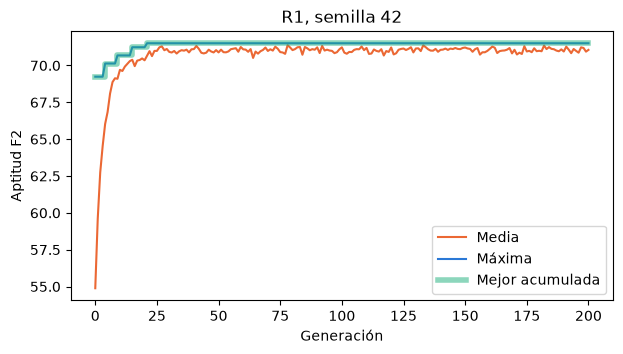

Mejor de la corrida: F = 71.509620 en la generación 21; evaluaciones solicitadas 16115, efectivas 678


In [8]:
log = pd.DataFrame(res.log)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(log.generacion, log.aptitud_media, label="Media", color="#eb6834")
ax.plot(log.generacion, log.aptitud_max, label="Máxima", color="#2a78d6")
ax.step(log.generacion, log.mejor_acumulada, where="post", label="Mejor acumulada", color="#1baf7a", alpha=0.5, linewidth=4)
ax.set_xlabel("Generación"); ax.set_ylabel("Aptitud F2"); ax.legend(); ax.set_title("R1, semilla 42")
plt.show()
print(f"Mejor de la corrida: F = {res.best_fitness:.6f} en la generación {res.best_generation}; "
      f"evaluaciones solicitadas {res.evals_requested}, efectivas {res.evals_effective}")

## 6. Resultados del lote y referencia exacta

El lote corre cada configuración de `config/experiments.json` con las semillas 42–51: los cinco perfiles de
pesos (R1–R5), la versión original como referencia (ORIG-R1: aptitud F1 y cruza binomial aleatoria) y las
variantes de operadores (OP-...). Como el espacio tiene 292.825 combinaciones, también se puede **enumerar
completo** con la misma función: eso da el óptimo demostrado de cada perfil y permite medir la brecha del AG.
Que la enumeración sea viable es un resultado en sí mismo.

In [9]:
runs = pd.read_csv(ROOT / "results" / "summary_runs.csv")
summary = pd.read_csv(ROOT / "results" / "summary_configs.csv")
quality = pd.read_csv(ROOT / "results" / "quality_assessment.csv")
print(f"{len(summary)} configuraciones × {runs.semilla.nunique()} semillas = {len(runs)} corridas; "
      f"alcanzan el óptimo de su perfil: {quality.replicas_alcanzan_optimo.sum()} de {quality.replicas.sum()}")
summary[["config_id", "aptitud_media", "aptitud_desvio", "aptitud_min", "aptitud_max", "generacion_encontrada_media", "moveset_modal"]].merge(
    quality[["config_id", "replicas_alcanzan_optimo"]], on="config_id")

15 configuraciones × 10 semillas = 150 corridas; alcanzan el óptimo de su perfil: 143 de 150


,config_id,aptitud_media,aptitud_desvio,aptitud_min,aptitud_max,generacion_encontrada_media,moveset_modal,replicas_alcanzan_optimo
0,R1,71.509620,0.000000,71.509620,71.509620,16.4,earthquake|fire-blast|focus-blast|hurricane,10
1,R2,74.605696,0.000000,74.605696,74.605696,43.8,earthquake|crunch|focus-blast|hurricane,10
2,R3,78.509493,0.000000,78.509493,78.509493,12.0,earthquake|fire-blast|focus-blast|hurricane,10
3,R4,79.268890,0.000000,79.268890,79.268890,15.0,flamethrower|earthquake|crunch|air-slash,10
4,R5,71.436035,0.000000,71.436035,71.436035,16.1,earthquake|fire-blast|focus-blast|hurricane,10
5,ORIG-R1,72.784722,0.000000,72.784722,72.784722,19.5,fly|solar-beam|earthquake|focus-punch,10
6,OP-UNIF,71.509620,0.000000,71.509620,71.509620,24.7,earthquake|fire-blast|focus-blast|hurricane,10
7,OP-1P,71.509620,0.000000,71.509620,71.509620,29.4,earthquake|fire-blast|focus-blast|hurricane,10
8,OP-RUL,71.509620,0.000000,71.509620,71.509620,38.9,earthquake|fire-blast|focus-blast|hurricane,10
9,OP-RANK,71.509620,0.000000,71.509620,71.509620,20.3,earthquake|fire-blast|focus-blast|hurricane,10


In [10]:
table = exhaustive_table(catalog)                    # F2
opt = exhaustive_optimum(table, w_base)
print(f"Enumeración de {table.n:,} combinaciones en {table.seconds:.2f} s")
print("Óptimo R1 (F2):", round(opt["optimo"], 6), catalog.names(opt["movesets_optimos"][0]), "| empates:", opt["n_empates_optimo"])
print("Brecha del AG (R1, semilla 42):", opt["optimo"] - res.best_fitness)

# El óptimo de la versión original (F1) premia movimientos que en combate rinden mucho menos que su potencia base.
opt_f1 = exhaustive_optimum(exhaustive_table(catalog, version="F1"), w_base)
k1 = opt_f1["movesets_optimos"][0]
f2_of_k1 = fitness(k1, catalog, w_base)
print("Óptimo R1 con F1:", round(opt_f1["optimo"], 6), catalog.names(k1))
print(f"  medido con F2 vale {f2_of_k1:.6f} y queda en el puesto {rank_of(table, opt['fitness_array'], f2_of_k1):,} de {table.n:,}")

Enumeración de 292,825 combinaciones en 1.32 s
Óptimo R1 (F2): 71.50962 ['Terremoto', 'Llamarada', 'Onda Certera', 'Vendaval'] | empates: 1
Brecha del AG (R1, semilla 42): 0.0


Óptimo R1 con F1: 72.784722 ['Vuelo', 'Rayo Solar', 'Terremoto', 'Puño Certero']
  medido con F2 vale 65.811481 y queda en el puesto 4,174 de 292,825


## Conclusión de la demostración

- El AG encuentra, en esta corrida, la misma combinación que la enumeración exhaustiva; eso **no** demuestra
  que un AG garantice el óptimo: la garantía proviene de la enumeración. Con pocos recursos (OP-POB20:
  población 20 y 30 generaciones) el AG no siempre llega.
- Con la potencia efectiva (F2), el óptimo deja de apoyarse en movimientos que en combate rinden mucho menos que
  su potencia base (carga, recarga, fallo condicional). El óptimo de la versión original, medido con F2, queda
  muy lejos del primer puesto.
- La aptitud sigue siendo un indicador simplificado de calidad ofensiva: no modela objetos, habilidades, clima,
  prioridad, potencias condicionales ni la cobertura contra rivales de doble tipo.